# Taller 2 — Titanic: análisis exploratorio de datos (EDA)

**Pregunta central:** ¿qué factores tuvieron más influencia sobre la supervivencia de los pasajeros del Titanic?

Este cuaderno es de **exploración**: lee Bronze y Silver, produce gráficos y tablas, y deja la lógica productiva en `flows/`.
Las decisiones y su interpretación se resumen en `reports/conclusiones_eda.md`.

> Regla: si una celda calcula algo que otro proceso necesitará, ese cálculo vive en `flows/`, no aquí.


## 0. Preparación del entorno

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from flows.common.paths import BRONZE, BRONZE_LABELED_NAME, BRONZE_QUALITY_NAME, GOLD, SILVER

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.titlesize'] = 13
print('pandas', pd.__version__, '| seaborn', sns.__version__)

pandas 3.1.1 | seaborn 0.13.2


## Parte 1 — Primer contacto con los datos (Pasos 1–5)

Se empieza por **Bronze**, la copia sin retocar, para no ocultar problemas con la limpieza.

In [2]:
# 1) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

### Paso 1. ¿Cuántos pasajeros y variables hay?

In [3]:
df.shape

(891, 12)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


### Paso 3. Primeras 10 filas

In [5]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Paso 4. Estadísticas descriptivas

In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


### Paso 5. Datos faltantes: tabla, mapa de calor y reporte automático

Los nulos no son un detalle: **cómo se rellenen cambia las conclusiones**. Aquí solo los diagnosticamos.


In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

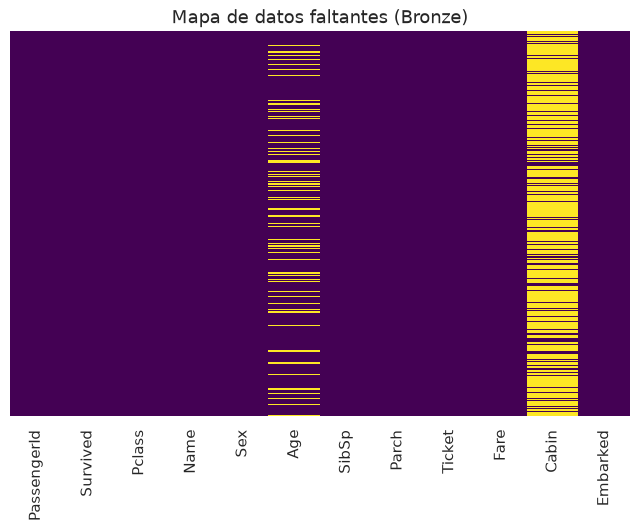

In [9]:
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de datos faltantes (Bronze)')
plt.show()

In [10]:
quality = json.loads((BRONZE / BRONZE_QUALITY_NAME).read_text(encoding='utf-8'))
pd.Series(quality['null_pct']).round(1).sort_values(ascending=False)

Cabin          77.5
Survived       31.9
Age            20.1
Embarked        0.2
Fare            0.1
Name            0.0
PassengerId     0.0
Pclass          0.0
Parch           0.0
SibSp           0.0
Sex             0.0
Ticket          0.0
dtype: float64

**Lectura.** De 891 pasajeros, a `Age` le faltan 177 (19,9 %), a `Cabin` 687 (77,1 %) y a `Embarked` 2 (0,2 %).
El mapa de calor no muestra una fila entera vacía: la pérdida está concentrada en columnas concretas.


## Parte 2 — Conociendo a los pasajeros (Pasos 6–10)

A partir de aquí se lee **Silver**: las columnas derivadas ya fueron calculadas por `flows/01_data_engineering.py`.


In [11]:
df = pd.read_parquet(SILVER / 'titanic_silver.parquet')
df.shape

(891, 25)

### Paso 6. Distribución por género y su cruce con la clase

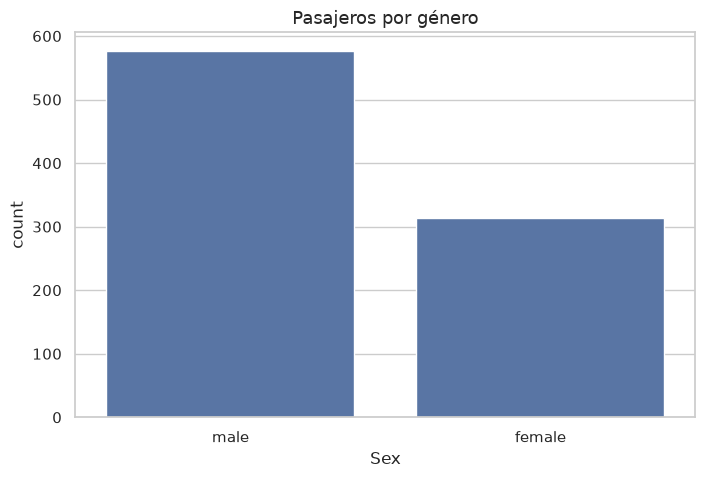

In [12]:
sns.countplot(data=df, x='Sex')
plt.title('Pasajeros por género')
plt.show()

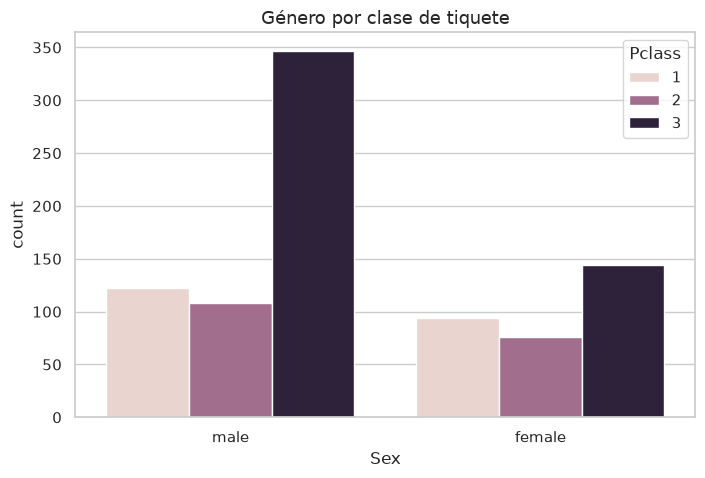

In [13]:
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Género por clase de tiquete')
plt.show()

In [14]:
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


### Paso 7. Distribución de edades

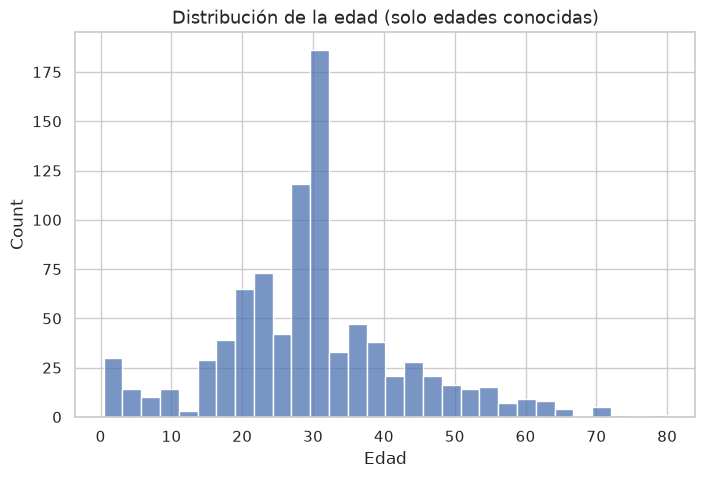

In [15]:
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de la edad (solo edades conocidas)')
plt.xlabel('Edad')
plt.show()

In [16]:
print('Media:', round(df['AgeOriginal'].mean(), 2))
print('Mediana:', df['AgeOriginal'].median())
print('Mínimo:', df['AgeOriginal'].min(), '| Máximo:', df['AgeOriginal'].max())

Media: 29.7
Mediana: 28.0
Mínimo: 0.42 | Máximo: 80.0


### Paso 8. Variable `Person` (hombre, mujer o niño)

Regla explícita: `Age < 16` → `child`; si no, se conserva `Sex`. Un pasajero **sin edad nunca es niño**
(`NaN < 16` es `False` en NumPy): se queda con su sexo. Ese sesgo se cuantifica más adelante.


In [17]:
df['Person'].value_counts()

Person
male      537
female    271
child      83
Name: count, dtype: int64

**Reto 8.1.** De los 177 pasajeros sin edad, muchos podrían ser niños. Si la proporción de niños
entre los que sí tienen edad (83 de 714 ≈ 11,6 %) se sostuviera, faltarían ~21 `child`. La tasa observada
de supervivencia infantil podría estar subestimada o diluida en las categorías `male`/`female`.


### Paso 9. Niños por clase

In [18]:
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


### Paso 10. Densidades (KDE) de la edad

`common_norm=False` normaliza cada curva por separado: así un grupo grande no "aplasta" a uno pequeño.


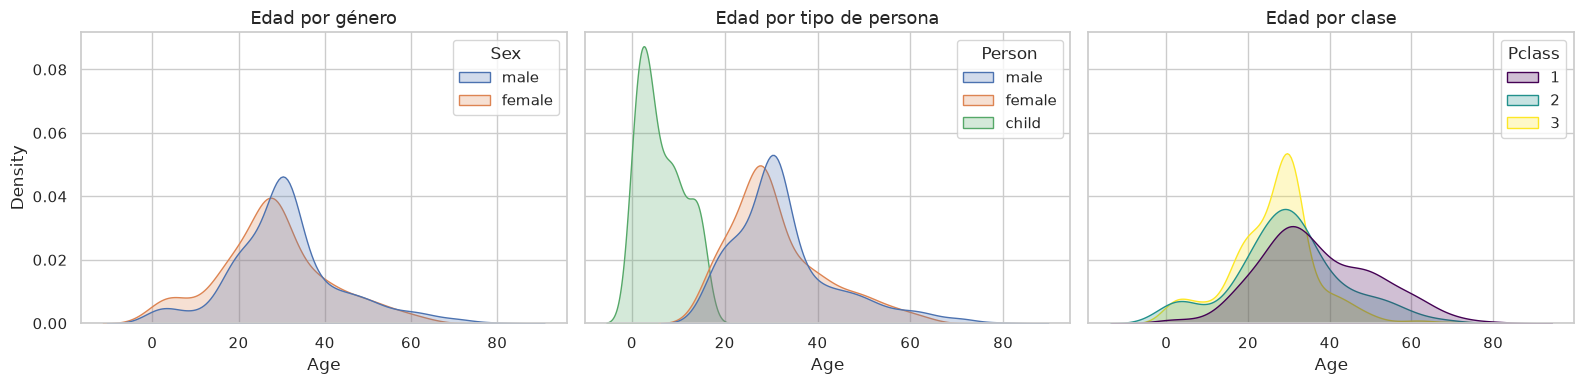

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Edad por género')
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Edad por tipo de persona')
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False,
            palette='viridis', ax=axes[2])
axes[2].set_title('Edad por clase')
plt.tight_layout()
plt.show()

## Parte 3 — Ubicación, embarque y composición familiar (Pasos 11–15)

### Paso 11. Cubierta de la cabina

`TCabin` es la primera letra de `Cabin`; `X` significa "desconocida" (una categoría explícita, no un borrado).
`HasCabin` marca si había cabina registrada. `Cabin` original se conserva en Silver.


In [20]:
df['TCabin'].value_counts()

TCabin
X    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64

### Paso 12. Conteo por cubierta (excluyendo lo desconocido y lo anómalo del gráfico)

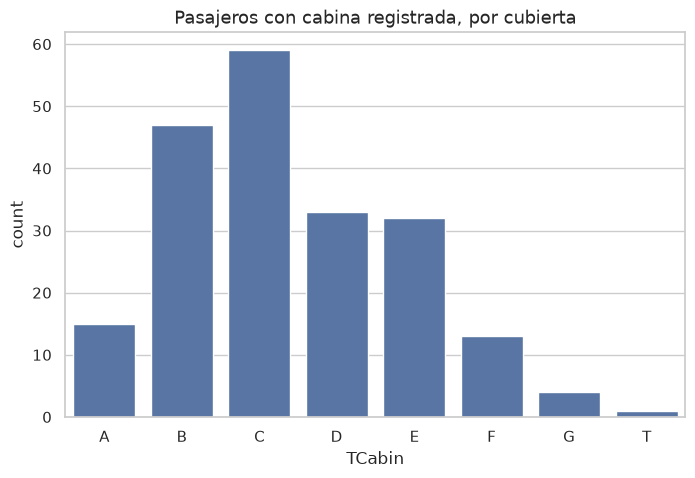

In [21]:
cubierta = df.loc[df['TCabin'] != 'X', 'TCabin']
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros con cabina registrada, por cubierta')
plt.show()

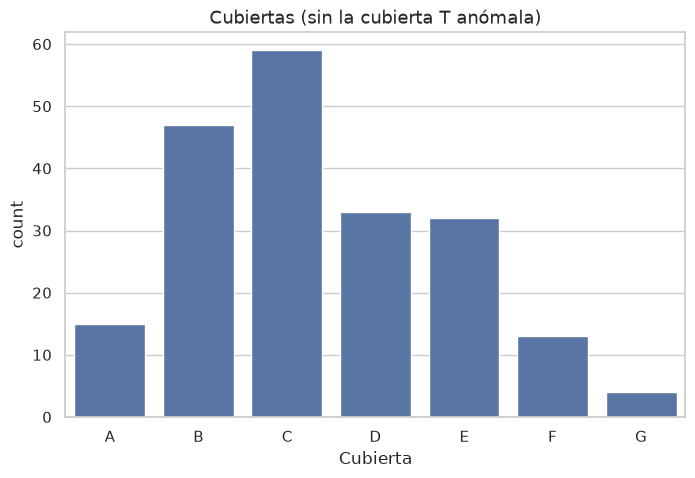

In [22]:
cubierta = cubierta[cubierta != 'T']   # 1 solo registro: se excluye del GRÁFICO, no de df
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Cubiertas (sin la cubierta T anómala)')
plt.xlabel('Cubierta')
plt.show()

### Paso 13. Puerto de embarque y clase

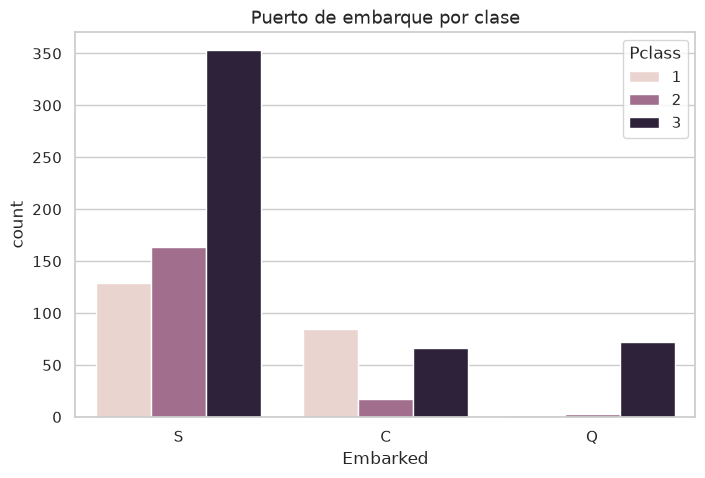

In [23]:
sns.countplot(data=df, x='Embarked', hue='Pclass')
plt.title('Puerto de embarque por clase')
plt.show()

In [24]:
pd.crosstab(df['Embarked'], df['Pclass'], normalize='index').round(3)

Pclass,1,2,3
Embarked,,,
C,0.506,0.101,0.393
Q,0.026,0.039,0.935
S,0.200,0.254,0.546


### Paso 14–15. Variable `Alone`

In [25]:
df['Alone'].value_counts(normalize=True).round(3)

Alone
Alone          0.603
with Family    0.397
Name: proportion, dtype: float64

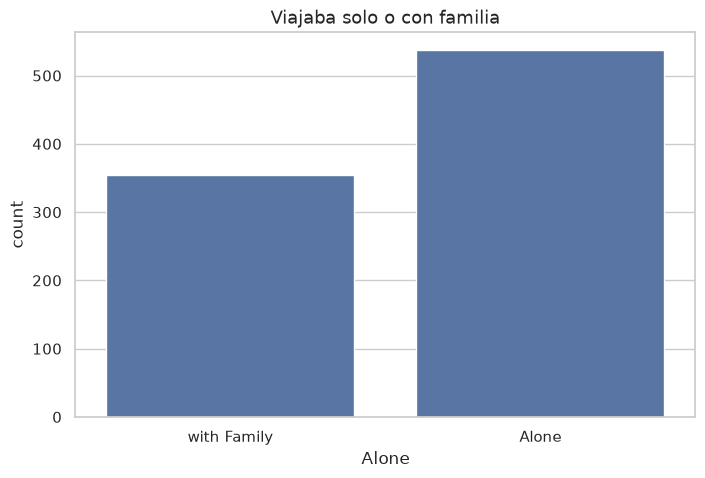

In [26]:
sns.countplot(data=df, x='Alone')
plt.title('Viajaba solo o con familia')
plt.show()

**Lectura.** 537 pasajeros (60,3 %) viajaban solos y 354 (39,7 %) con familia.
La composición por clase difiere mucho entre puertos: Queenstown es casi toda de 3.ª clase,
mientras Cherbourg tiene ~51 % de 1.ª. Eso será una **variable de confusión** en la Parte 9.


## Parte 4 — Análisis de supervivencia: el núcleo del EDA (Pasos 16–20)

La media de `Survived` (0/1) es la **tasa de supervivencia**. Las barras verticales de los gráficos de puntos
son intervalos de confianza al 95 %: miden incertidumbre, no importancia.


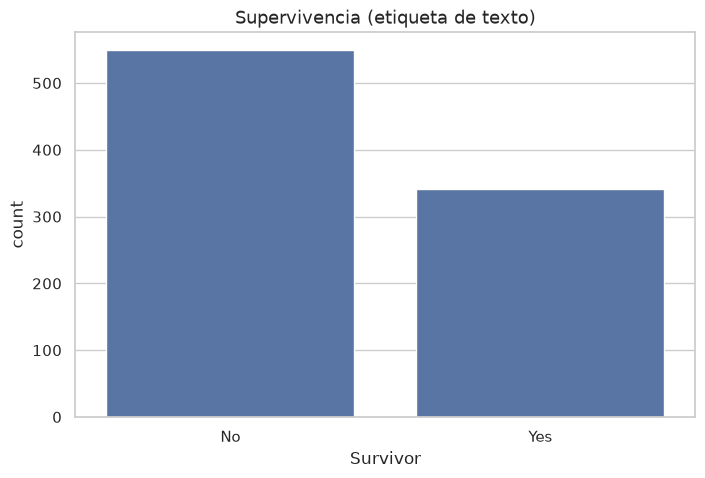

Tasa general: 0.3838


In [27]:
sns.countplot(data=df, x='Survivor')
plt.title('Supervivencia (etiqueta de texto)')
plt.show()
print('Tasa general:', round(df['Survived'].mean(), 4))

### Paso 17. Supervivencia por clase

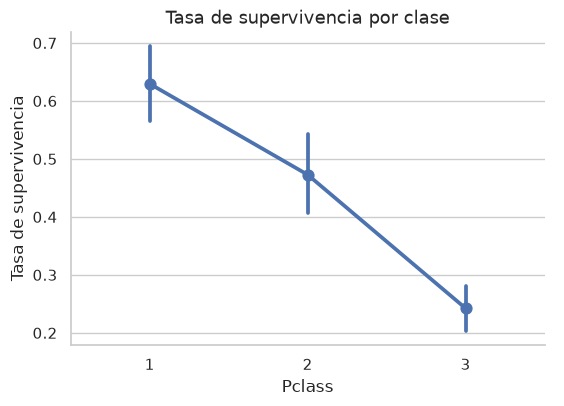

In [28]:
g = sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
g.ax.set_title('Tasa de supervivencia por clase')
g.ax.set_ylabel('Tasa de supervivencia')
plt.show()

### Paso 18. Supervivencia por clase y tipo de persona

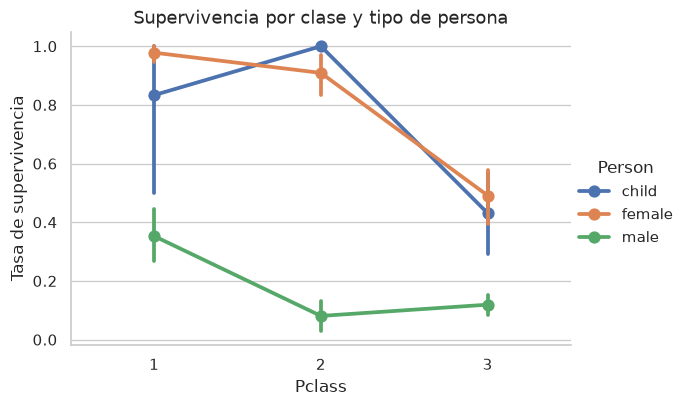

In [29]:
g = sns.catplot(data=df, x='Pclass', y='Survived', hue='Person',
                hue_order=['child', 'female', 'male'], kind='point', height=4, aspect=1.5)
g.ax.set_title('Supervivencia por clase y tipo de persona')
g.ax.set_ylabel('Tasa de supervivencia')
plt.show()

### Paso 19. Edad y supervivencia

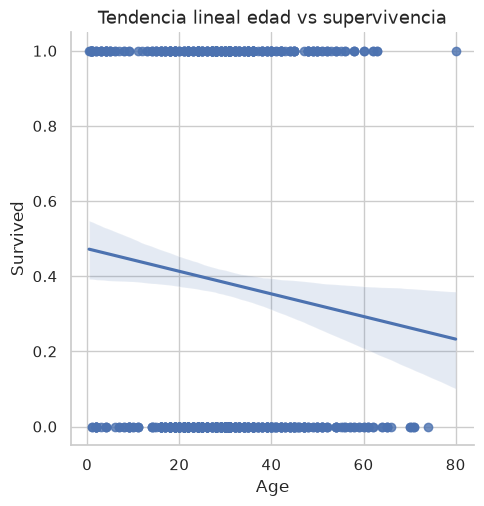

In [30]:
sns.lmplot(data=df, x='Age', y='Survived')
plt.title('Tendencia lineal edad vs supervivencia')
plt.show()

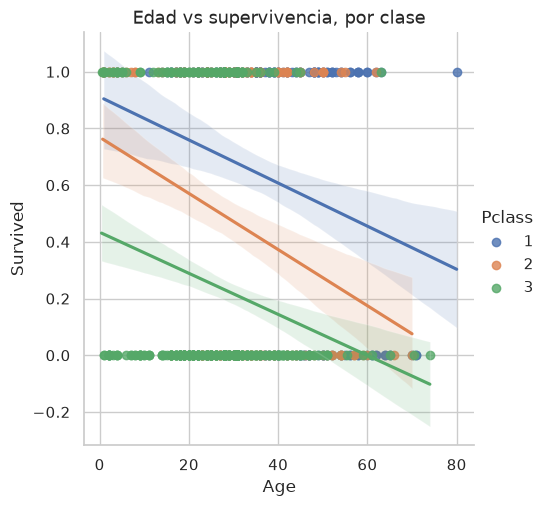

In [31]:
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass')
plt.title('Edad vs supervivencia, por clase')
plt.show()

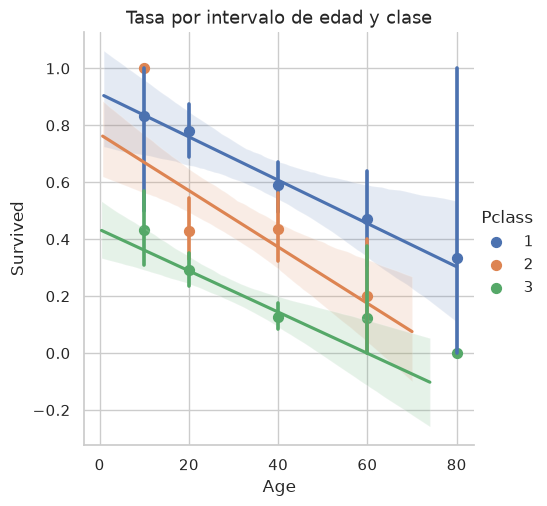

In [32]:
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones)
plt.title('Tasa por intervalo de edad y clase')
plt.show()

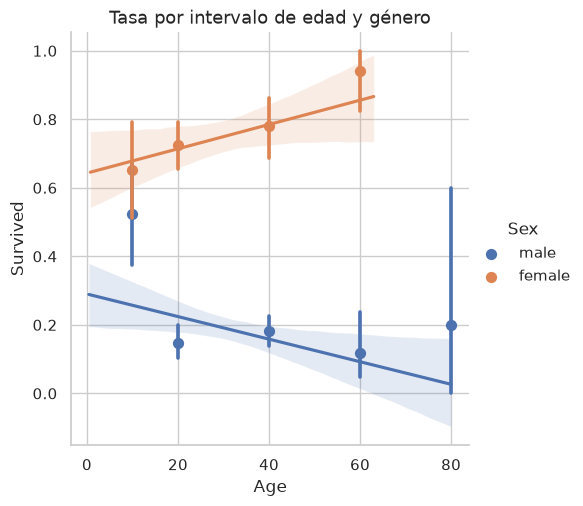

In [33]:
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones)
plt.title('Tasa por intervalo de edad y género')
plt.show()

### Paso 20. Relación tarifa–edad

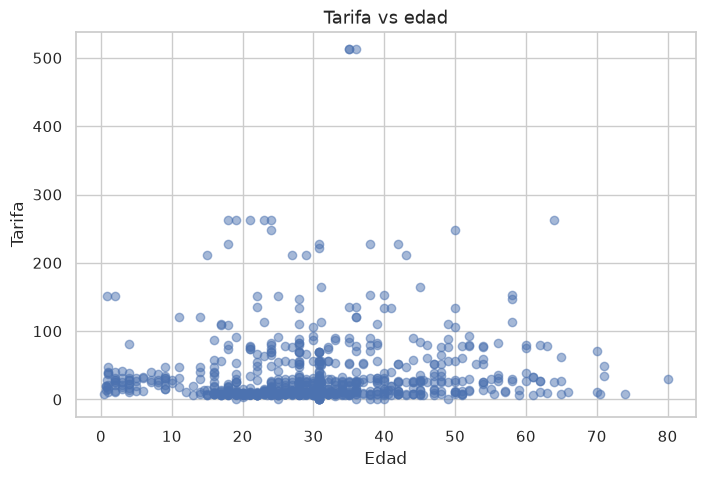

In [34]:
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Tarifa vs edad')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.show()

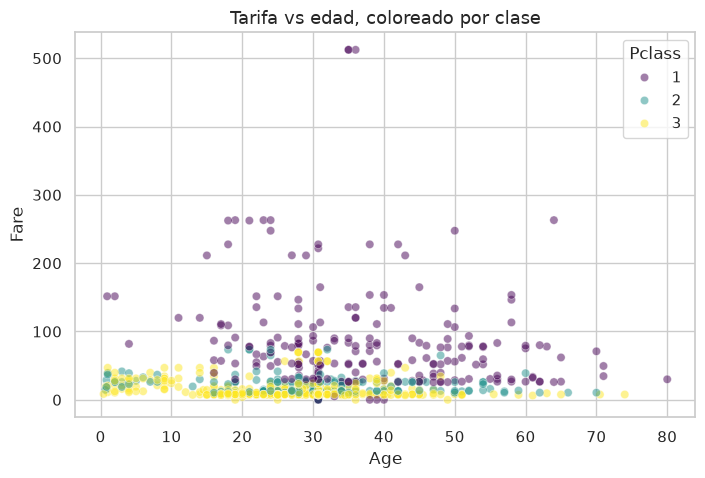

In [35]:
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Tarifa vs edad, coloreado por clase')
plt.show()

## Parte 5 — Limpieza y preparación (Pasos 21–26)

### Paso 21. `Embarked`: moda y codificación

In [36]:
print('Faltantes en Bronze:', 2)
print('Moda:', df['Embarked'].mode()[0])
df[['Embarked', 'NEmbarked']].drop_duplicates().sort_values('Embarked')

Faltantes en Bronze: 2
Moda: S


,Embarked,NEmbarked
1,C,1
5,Q,2
0,S,0


### Paso 22. `Age`: imputación por género y su costo

In [37]:
print('Desv. estándar con edad original:', round(df['AgeOriginal'].std(), 2))
print('Desv. estándar tras imputar:      ', round(df['Age'].std(), 2))
print('Filas imputadas:', int(df['AgeImputada'].sum()))

Desv. estándar con edad original: 14.53
Desv. estándar tras imputar:       13.01
Filas imputadas: 177


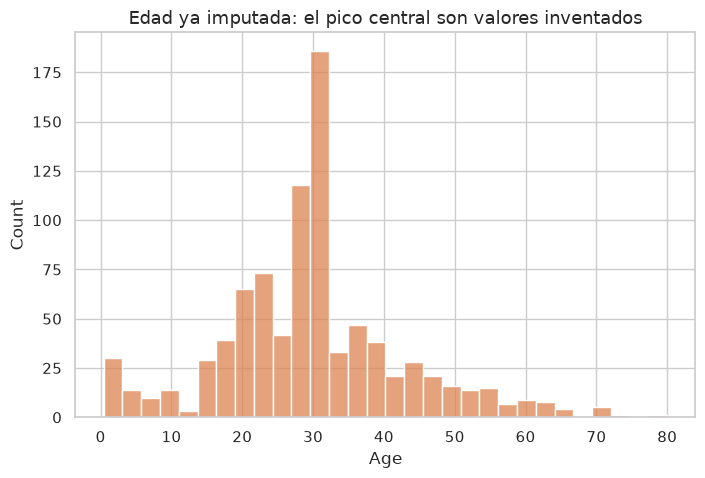

In [38]:
sns.histplot(df['Age'].dropna(), bins=30, color='C1')
plt.title('Edad ya imputada: el pico central son valores inventados')
plt.show()

**Reto 22.1.** La desviación baja de 14,53 a 13,01 porque 177 valores se sustituyeron por promedios
de grupo: se reduce la variabilidad artificialmente y el histograma desarrolla un pico central que no
es datos reales. Para **explorar** está bien si se documenta; para **modelar** se vuelve a imputar dentro
del `Pipeline`, usando solo estadísticas de entrenamiento.


### Pasos 23–24. Codificaciones `NSex` y `NCabin`

In [39]:
df[['Sex', 'NSex']].drop_duplicates()

,Sex,NSex
0,male,1
1,female,0


In [40]:
df['NCabin'].value_counts().sort_index()

NCabin
0     15
1     47
2     59
3     33
4     32
5     13
6      4
7      1
8    687
Name: count, dtype: int64

El mapa de cubiertas es **fijo** (`DECKS = ABCDEFGTX`), no depende de qué categorías aparezcan en el
momento: así los resultados siguen siendo comparables entre ejecuciones. `X` (desconocida) queda como la
última categoría; el orden es una simplificación para correlaciones, no para modelar.


### Pasos 25–26. Títulos del nombre y su consolidación

In [41]:
df['TTitulo'].value_counts()

TTitulo
Mr      557
Miss    186
Mrs     127
Otro     21
Name: count, dtype: int64

In [42]:
pd.crosstab(df['TTitulo'], df['Sex'])

Sex,female,male
TTitulo,,
Miss,186,0
Mr,0,557
Mrs,127,0
Otro,1,20


In [43]:
df['NTitulo'].value_counts().sort_index()

NTitulo
0    557
1    127
2    186
3     21
Name: count, dtype: int64

**Cuestionamiento.** `Master` (niño varón) se fusionó con `Mr`. Esa decisión mezcla niños con adultos;
la compensa parcialmente `Person`, que usa la edad original. Es una simplificación defendible solo si se
documenta, como aquí.


## Parte 6 — Correlaciones y estadísticas por grupos (Pasos 27–29)

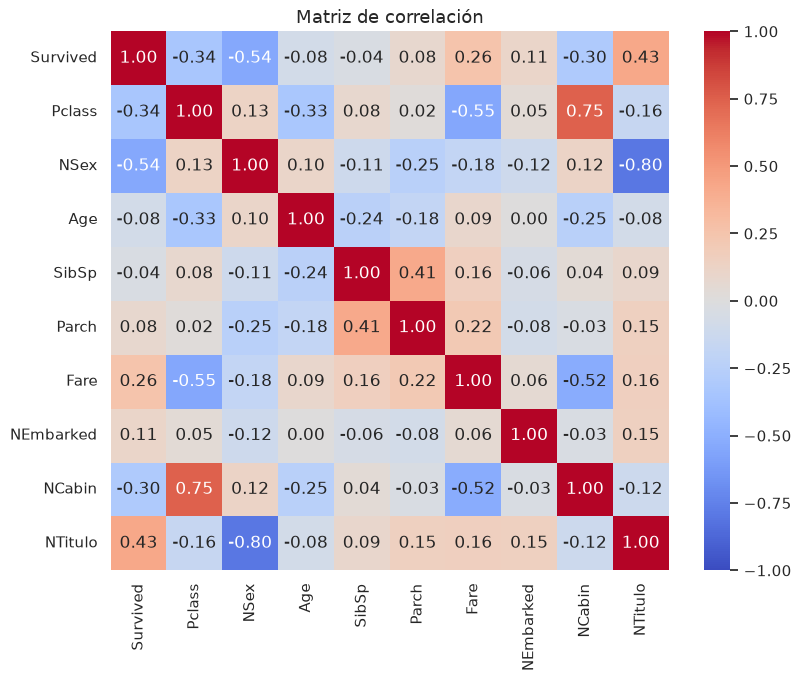

NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.080453
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64

In [44]:
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare',
        'NEmbarked', 'NCabin', 'NTitulo']
corr = df[cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()
corr['Survived'].sort_values()

**Recordatorio.** Correlación lineal ≠ causalidad, y las codificaciones `N…` imponen un orden
arbitrario: el signo de `NCabin` no tiene interpretación sustantiva.


### Paso 28. Estadísticas por grupos (tablas Gold)

In [45]:
for name in ['age_by_survival', 'survival_by_sex', 'survival_by_pclass', 'survival_by_alone']:
    print('\n---', name, '---')
    display(pd.read_parquet(GOLD / f'{name}.parquet').round(3))


--- age_by_survival ---


,Survived,count,mean,std,min,25%,50%,75%,max
0,0,549.0,30.562,12.460,1.00,23.0,30.727,35.0,74.0
1,1,342.0,28.410,13.774,0.42,21.0,27.916,35.0,80.0



--- survival_by_sex ---


,Sex,mean,sum,count
0,female,0.742,233,314
1,male,0.189,109,577



--- survival_by_pclass ---


,Pclass,mean,sum,count
0,1,0.630,136,216
1,2,0.473,87,184
2,3,0.242,119,491



--- survival_by_alone ---


,Alone,mean,sum,count
0,Alone,0.304,163,537
1,with Family,0.506,179,354


### Paso 29. ¿Es la diferencia por sexo estadísticamente significativa?

In [46]:
chi2 = json.loads((GOLD / 'chi2_sex_survival.json').read_text(encoding='utf-8'))
chi2

{'chi2': 260.71702016732104, 'p_value': 1.1973570627755645e-58, 'dof': 1}

**Conclusión con límites.** χ² ≈ 260,7, gl = 1, p ≈ 1,2e-58: rechazamos la independencia entre
sexo y supervivencia. Esto dice que la asociación es muy improbable que sea azar; **no** dice que sea grande,
ni que el sexo *causara* la supervivencia, ni que el mismo patrón deba operar hoy.


## Parte 7 — Visualizaciones comparativas avanzadas (Pasos 30–31)

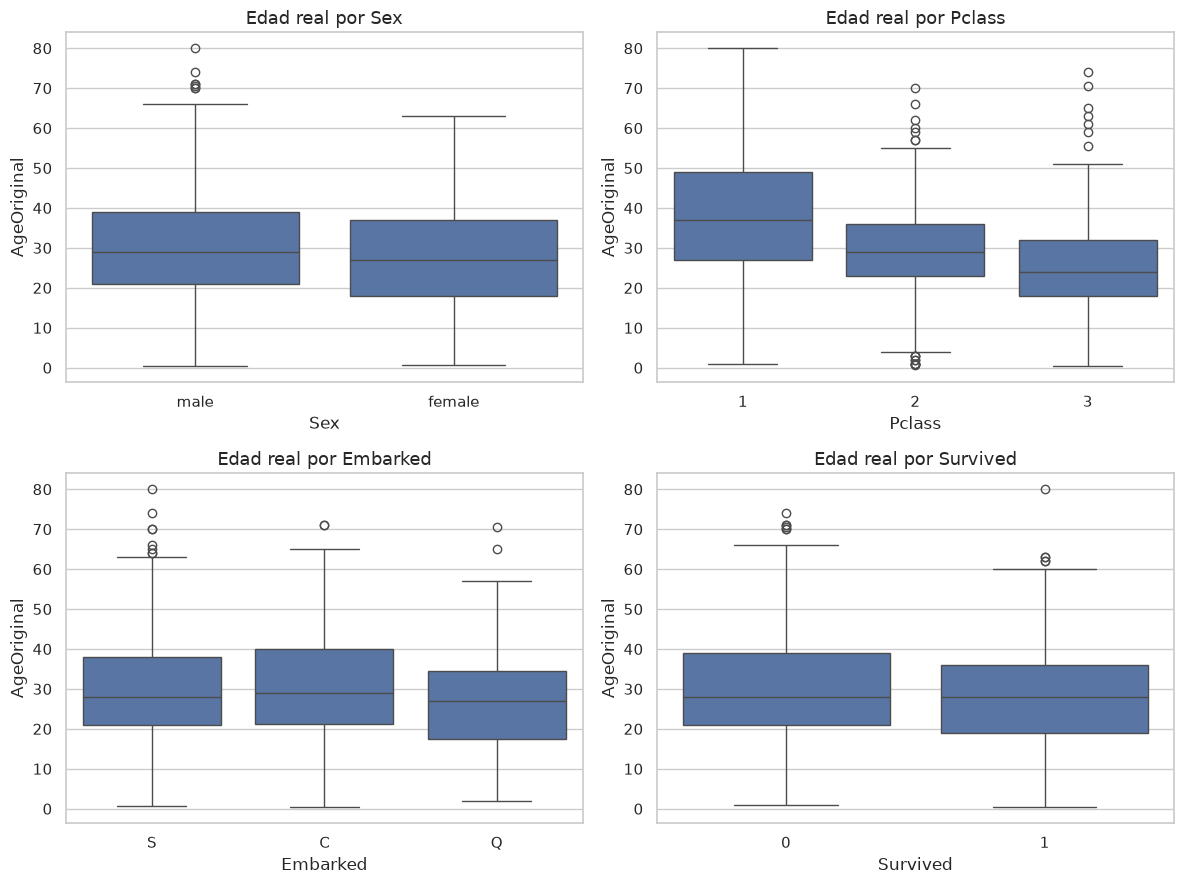

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, ['Sex', 'Pclass', 'Embarked', 'Survived']):
    sns.boxplot(data=df, x=col, y='AgeOriginal', ax=ax)   # edades REALES, no imputadas
    ax.set_title(f'Edad real por {col}')
plt.tight_layout()
plt.show()

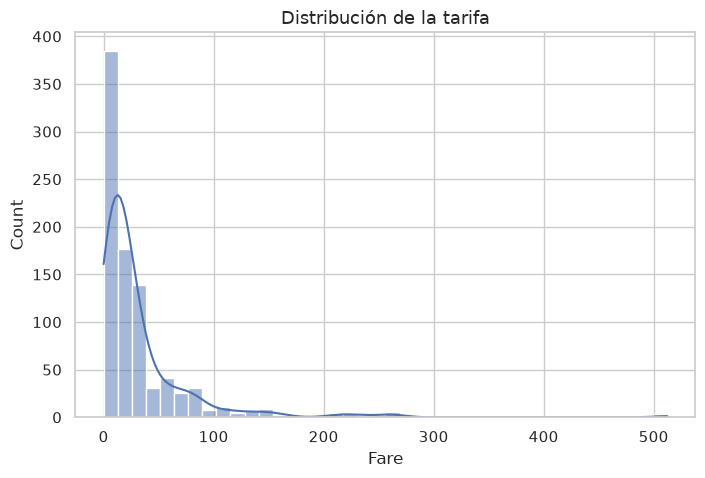

Media: 32.2 | Mediana: 14.45 | Asimetría: 4.79


In [48]:
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa')
plt.show()
print('Media:', round(df['Fare'].mean(), 2), '| Mediana:', round(df['Fare'].median(), 2),
      '| Asimetría:', round(df['Fare'].skew(), 2))

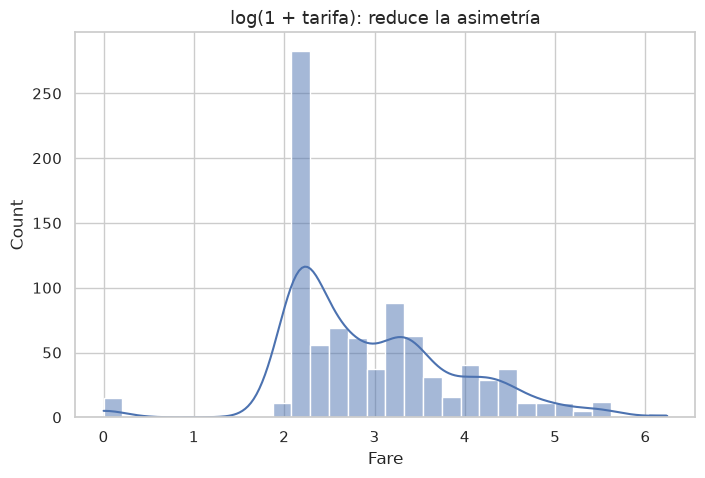

In [49]:
sns.histplot(np.log1p(df['Fare']), kde=True, bins=30)
plt.title('log(1 + tarifa): reduce la asimetría')
plt.show()

La tarifa es muy asimétrica (skew ≈ 4,8): la media (32,2) está lejos de la mediana (14,5).
Un modelo lineal que use `Fare` sin transformar puede verse dominado por unas pocas tarifas extremas.


## Parte 8 — Dataset final y verificación (Pasos 32–33)

In [50]:
final = pd.read_parquet(SILVER / 'titanic_final.parquet')
print('Silver completo:', df.shape, '| vista final:', final.shape)
print('Columnas eliminadas en la copia:', {'Name', 'Sex', 'Embarked', 'Cabin'} & set(df.columns))
final.isnull().sum().sort_values(ascending=False).head()

Silver completo: (891, 25) | vista final: (891, 21)
Columnas eliminadas en la copia: {'Sex', 'Cabin', 'Embarked', 'Name'}


AgeOriginal    177
Survived         0
Pclass           0
Age              0
PassengerId      0
dtype: int64

In [51]:
final.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Person             str
TCabin             str
HasCabin         int64
Familia          int64
Alone              str
Survivor           str
TTitulo            str
AgeOriginal    float64
AgeImputada       bool
NEmbarked        int64
NSex             int64
NCabin           int64
NTitulo          int64
dtype: object

`AgeOriginal` conserva sus NaN a propósito: es la verdad observada. `validate_silver` exige sin nulos
en las columnas críticas, pero explícitamente permite nulos en `AgeOriginal`.


## Parte 9 — Análisis crítico: interacciones, asociaciones y atípicos (Pasos 34–38)

### Paso 34. Clase × género

,Pclass,female,male
0,1,0.968,0.369
1,2,0.921,0.157
2,3,0.500,0.135


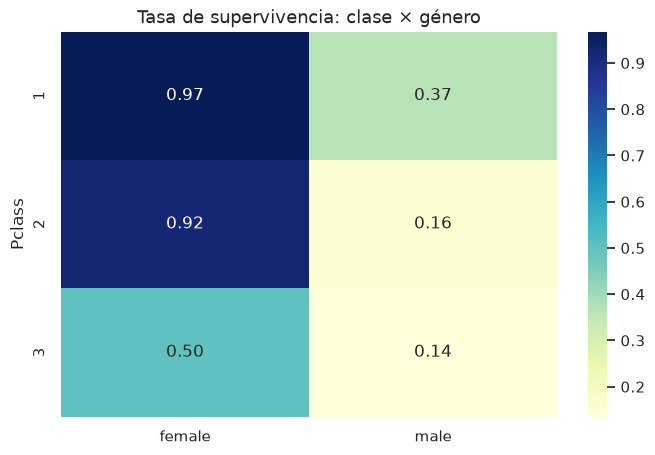

In [52]:
tabla = pd.read_parquet(GOLD / 'survival_by_class_sex.parquet')
display(tabla.round(3))
sns.heatmap(tabla.set_index('Pclass'), annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Tasa de supervivencia: clase × género')
plt.show()

Las mujeres de 1.ª y 2.ª clase sobreviven en ~97 % y ~92 % (n = 144 y 93); los hombres de 3.ª,
solo ~13,5 % (n = 347). La interacción importa: el efecto del género no es igual en todas las clases.


### Paso 35. Puerto de embarque: ¿confusión con la clase?

,Embarked,mean,count
0,C,0.554,168
1,Q,0.390,77
2,S,0.339,646


,Embarked,1,2,3
0,C,0.694,0.529,0.379
1,Q,0.500,0.667,0.375
2,S,0.589,0.463,0.190


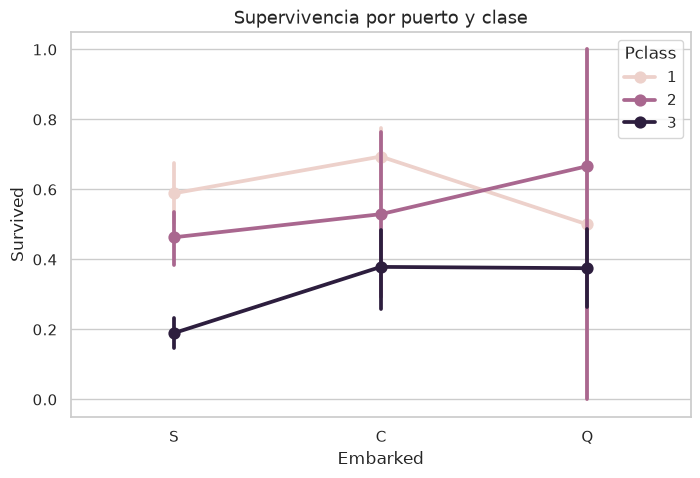

In [53]:
display(pd.read_parquet(GOLD / 'survival_by_embarked.parquet').round(3))
display(pd.read_parquet(GOLD / 'survival_by_embarked_class.parquet').round(3))
sns.pointplot(data=df, x='Embarked', y='Survived', hue='Pclass')
plt.title('Supervivencia por puerto y clase')
plt.show()

En bruto, Cherbourg parece "mejor" (55,4 %) que Southampton (33,9 %). Al estratificar por clase,
la ventaja se reduce dentro de cada clase (p. ej. en 3.ª: 37,9 % vs 19,0 % sigue habiendo diferencia, pero
parte del efecto bruto venía de que Cherbourg traía más pasajeros de 1.ª). Estratificar separa la confusión.


### Paso 36. Tarifa dentro de cada clase

In [54]:
# El cuartil se calcula DENTRO de cada clase (de lo contrario sería un proxy de Pclass).
# La tabla Gold ya lo aplica en flows/03_aggregation.py; aquí lo replicamos para graficar.
df_con_q = df.copy()
df_con_q['FareQ'] = df_con_q.groupby('Pclass')['Fare'].transform(
    lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))

,FareQ,1,2,3
0,0,0.463,0.345,0.227
1,1,0.574,0.500,0.200
2,2,0.745,0.585,0.276
3,3,0.736,0.590,0.283


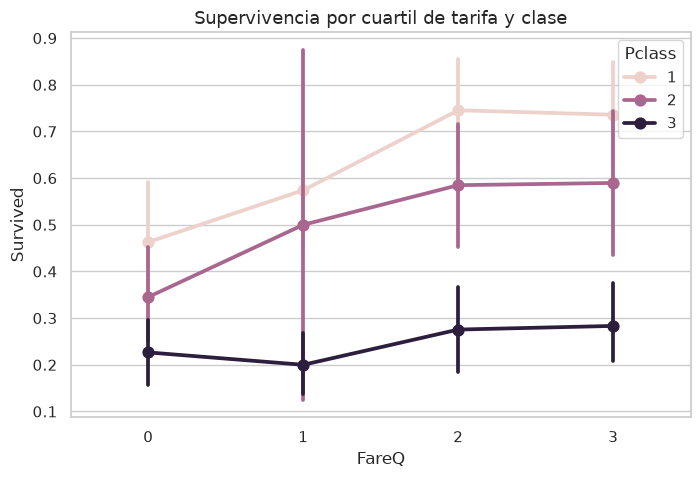

In [55]:
display(pd.read_parquet(GOLD / 'survival_by_fare_quartile_class.parquet').round(3))
sns.pointplot(data=df_con_q, x='FareQ', y='Survived', hue='Pclass', errorbar='ci')
plt.title('Supervivencia por cuartil de tarifa y clase')
plt.show()

Dentro de 1.ª clase, pagar más en el propio cuartil se asocia con tasas de 46 % → 57 % → 75 % → 74 %.
Pero `Fare` y `Pclass` están fuertemente correlacionadas: sin estratificar, la tarifa sería un proxy de clase.


### Paso 37. Tamaño de la familia

,Familia,mean,count
0,0,0.304,537
1,1,0.553,161
2,2,0.578,102
3,3,0.724,29
4,4,0.200,15
5,5,0.136,22
6,6,0.333,12
7,7,0.000,6
8,10,0.000,7


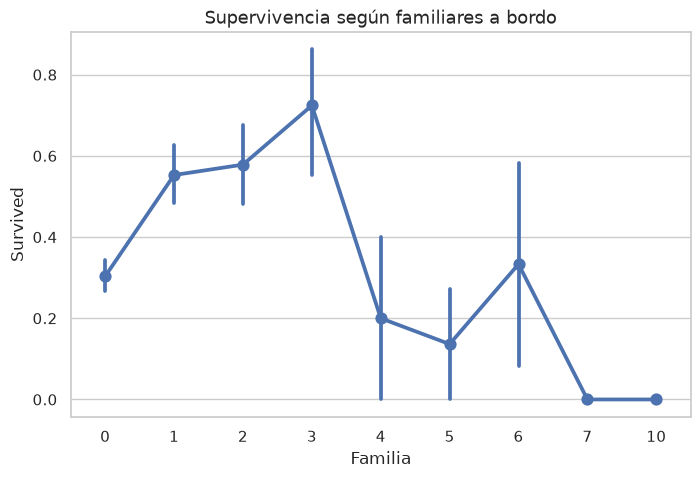

In [56]:
familia = pd.read_parquet(GOLD / 'survival_by_family.parquet')
display(familia.round(3))
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Supervivencia según familiares a bordo')
plt.show()

Familias pequeñas (1–3 familiares: 55 %–72 %, n = 161/102/29) sobreviven más que quienes viajan solos
(30 %, n = 537) o con 5+ (≈ 14 % o 0 %, n = 22/6/7). Las barras de error se disparan en familias grandes:
son grupos de menos de 20 personas, así que no conviene afirmar un "número óptimo" con precisión.


### Paso 38. Atípicos (regla IQR)

In [57]:
display(pd.read_parquet(GOLD / 'outlier_summary.parquet').round(3))
df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Fare', 'Survived']]

,variable,n_outliers,pct_outliers,survival_rate_outliers,survival_rate_rest
0,Fare,116,13.019,0.681,0.339
1,Age,11,1.235,NaN,NaN
2,Familia,91,10.213,NaN,NaN


,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,1
341,"Fortune, Miss. Alice Elizabeth",1,263.0000,1
438,"Fortune, Mr. Mark",1,263.0000,0
311,"Ryerson, Miss. Emily Borie",1,262.3750,1
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750,1
118,"Baxter, Mr. Quigg Edmond",1,247.5208,0


116 tarifas (13 %) son atípicas por IQR y sobrevivió el 68,1 % de ellas frente al 33,9 % del resto.
Pero son en su mayoría pasajeros de 1.ª clase: **atípico no significa erróneo ni protector**. Eliminarlos
sin inspeccionarlos borraría justo al grupo con más supervivencia.


## Conclusión del EDA

1. **Género y clase** son las asociaciones más fuertes: mujeres 74,2 % (n = 314) vs hombres 18,9 % (n = 577);
   1.ª clase 63,0 % (n = 216) vs 3.ª 24,2 % (n = 491).
2. **"Mujeres y niños primero"** se cumple en términos generales, con excepciones: en 3.ª clase la tasa
   femenina cae a 50 % y los niños de 1.ª tienen intervalos muy anchos por falta de muestra.
3. **Familia pequeña** se asocia con mayor supervivencia; las familias grandes tienen muestras mínimas.
4. **Datos faltantes y decisiones de limpieza importan**: 177 edades imputadas por género reducen la desviación
   de 14,5 a 13,0; 687 cabinas desconocidas se convirtieron en `X`; `Master` se fusionó con `Mr`.
5. **Lo que NO podemos afirmar**: asociación no es causalidad; es un solo naufragio; la información de cabina
   pudo registrarse de forma distinta para supervivientes; y los subgrupos pequeños no permiten generalizar.

La formulación del problema predictivo y sus límites están en `reports/problema_ml.md`.
